<a href="https://colab.research.google.com/github/shahabzaman718-cmyk/new-project/blob/main/Superconductor_Colab_Three_Models_Evaluation_(1)_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
# Run this cell FIRST in Google Colab.
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Direct paths to files on disk
train_path = "/content/train.csv"
composition_path = "/content/unique_m.csv"

print("Setup complete. Files are ready to be read directly from local storage.")

Setup complete. Files are ready to be read directly from local storage.


In [21]:
# Load the CSV datasets directly from local storage
train = pd.read_csv(train_path)
composition = pd.read_csv(composition_path)

print("train shape:", train.shape)
print("composition shape:", composition.shape)

display(train.head())
display(composition.head())

train shape: (21263, 82)
composition shape: (21263, 88)


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
0,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,29.0,Ba0.2La1.8Cu1O4
1,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,26.0,Ba0.1La1.9Ag0.1Cu0.9O4
2,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,19.0,Ba0.1La1.9Cu1O4
3,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,22.0,Ba0.15La1.85Cu1O4
4,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,23.0,Ba0.3La1.7Cu1O4


In [22]:
print("Calculated features:")
display(train.head())

print("\nChemical compositions:")
display(composition.head())

print("\ntrain.csv information:")
train.info()

print("\nunique_m.csv information:")
composition.info()

print("\nSummary statistics for calculated features:")
display(train.describe().T)

print("\nSummary statistics for compositions:")
display(composition.describe().T)

Calculated features:


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0



Chemical compositions:


,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
0,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,29.0,Ba0.2La1.8Cu1O4
1,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,26.0,Ba0.1La1.9Ag0.1Cu0.9O4
2,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,19.0,Ba0.1La1.9Cu1O4
3,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,22.0,Ba0.15La1.85Cu1O4
4,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,23.0,Ba0.3La1.7Cu1O4



train.csv information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21263 entries, 0 to 21262
Data columns (total 82 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   number_of_elements               21263 non-null  int64  
 1   mean_atomic_mass                 21263 non-null  float64
 2   wtd_mean_atomic_mass             21263 non-null  float64
 3   gmean_atomic_mass                21263 non-null  float64
 4   wtd_gmean_atomic_mass            21263 non-null  float64
 5   entropy_atomic_mass              21263 non-null  float64
 6   wtd_entropy_atomic_mass          21263 non-null  float64
 7   range_atomic_mass                21263 non-null  float64
 8   wtd_range_atomic_mass            21263 non-null  float64
 9   std_atomic_mass                  21263 non-null  float64
 10  wtd_std_atomic_mass              21263 non-null  float64
 11  mean_fie                         21263 non-null  float64

,count,mean,std,min,25%,50%,75%,max
number_of_elements,21263.0,4.115224,1.439295,1.000000,3.000000,4.000000,5.000000,9.0000
mean_atomic_mass,21263.0,87.557631,29.676497,6.941000,72.458076,84.922750,100.404410,208.9804
wtd_mean_atomic_mass,21263.0,72.988310,33.490406,6.423452,52.143839,60.696571,86.103540,208.9804
gmean_atomic_mass,21263.0,71.290627,31.030272,5.320573,58.041225,66.361592,78.116681,208.9804
wtd_gmean_atomic_mass,21263.0,58.539916,36.651067,1.960849,35.248990,39.918385,73.113234,208.9804
...,...,...,...,...,...,...,...,...
range_Valence,21263.0,2.041010,1.242345,0.000000,1.000000,2.000000,3.000000,6.0000
wtd_range_Valence,21263.0,1.483007,0.978176,0.000000,0.921454,1.063077,1.918400,6.9922
std_Valence,21263.0,0.839342,0.484676,0.000000,0.451754,0.800000,1.200000,3.0000
wtd_std_Valence,21263.0,0.673987,0.455580,0.000000,0.306892,0.500000,1.020436,3.0000



Summary statistics for compositions:


,count,mean,std,min,25%,50%,75%,max
H,21263.0,0.017685,0.267220,0.00000,0.000,0.0,0.0,14.0
He,21263.0,0.000000,0.000000,0.00000,0.000,0.0,0.0,0.0
Li,21263.0,0.012125,0.129552,0.00000,0.000,0.0,0.0,3.0
Be,21263.0,0.034638,0.848541,0.00000,0.000,0.0,0.0,40.0
B,21263.0,0.142594,1.044486,0.00000,0.000,0.0,0.0,105.0
...,...,...,...,...,...,...,...,...
Bi,21263.0,0.201009,0.655927,0.00000,0.000,0.0,0.0,14.0
Po,21263.0,0.000000,0.000000,0.00000,0.000,0.0,0.0,0.0
At,21263.0,0.000000,0.000000,0.00000,0.000,0.0,0.0,0.0
Rn,21263.0,0.000000,0.000000,0.00000,0.000,0.0,0.0,0.0


In [23]:
for name, df in [("train.csv", train), ("unique_m.csv", composition)]:
    print(f"\n{name}")

    print("Total missing values:", df.isna().sum().sum())
    print("Exact duplicate rows:", df.duplicated().sum())

    missing = df.isna().sum()
    display(missing[missing > 0].to_frame("Missing values"))

    constant_columns = df.columns[df.nunique(dropna=False) <= 1].tolist()
    print("Constant columns:", constant_columns)

    numeric = df.select_dtypes(include=np.number)
    print("Infinite values:", np.isinf(numeric.to_numpy()).sum())


train.csv
Total missing values: 0
Exact duplicate rows: 66


,Missing values


Constant columns: []
Infinite values: 0

unique_m.csv
Total missing values: 0
Exact duplicate rows: 0


,Missing values


Constant columns: ['He', 'Ne', 'Ar', 'Kr', 'Xe', 'Pm', 'Po', 'At', 'Rn']
Infinite values: 0


In [24]:
assert len(train) == len(composition), "The files have different row counts."

assert np.allclose(
    train["critical_temp"],
    composition["critical_temp"],
    rtol=0,
    atol=1e-8
), "Critical temperatures do not match row by row."

# Attach formulas by their original row positions.
# Do not merge on critical_temp: many materials share the same temperature.
eda = train.copy()
eda["material"] = composition["material"].to_numpy()

print("The target values match row by row.")
display(eda[["material", "number_of_elements", "critical_temp"]].head())

The target values match row by row.


,material,number_of_elements,critical_temp
0,Ba0.2La1.8Cu1O4,4,29.0
1,Ba0.1La1.9Ag0.1Cu0.9O4,5,26.0
2,Ba0.1La1.9Cu1O4,4,19.0
3,Ba0.15La1.85Cu1O4,4,22.0
4,Ba0.3La1.7Cu1O4,4,23.0


,Critical temperature (K)
count,21263.000000
mean,34.421219
std,34.254362
min,0.000210
1%,0.115000
25%,5.365000
50%,20.000000
75%,63.000000
90%,89.000000
95%,94.000000


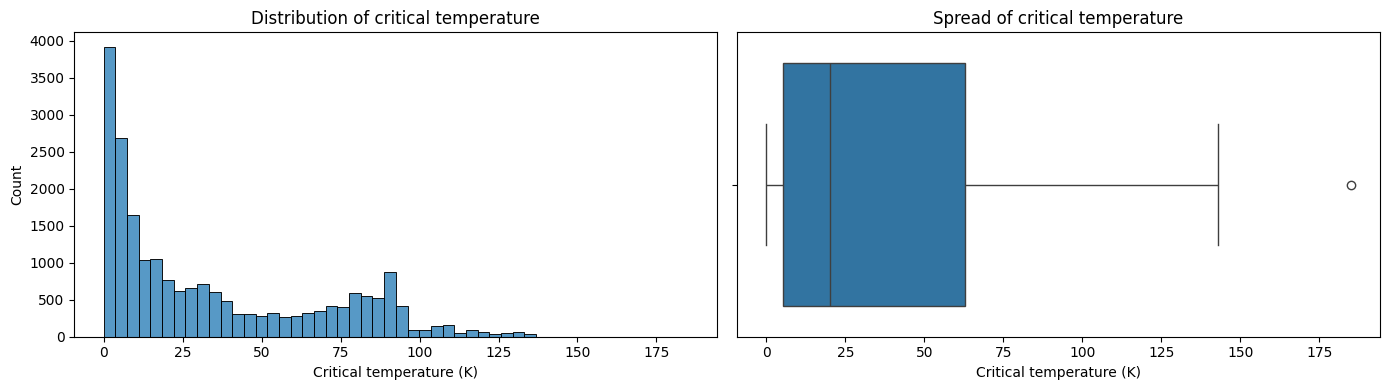

Skewness: 0.86
Non-positive temperatures: 0


In [25]:
display(
    train["critical_temp"].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("Critical temperature (K)")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(
    data=train,
    x="critical_temp",
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Distribution of critical temperature")
axes[0].set_xlabel("Critical temperature (K)")

sns.boxplot(
    data=train,
    x="critical_temp",
    ax=axes[1]
)
axes[1].set_title("Spread of critical temperature")
axes[1].set_xlabel("Critical temperature (K)")

plt.tight_layout()
plt.show()

print("Skewness:", round(train["critical_temp"].skew(), 3))
print("Non-positive temperatures:", (train["critical_temp"] <= 0).sum())

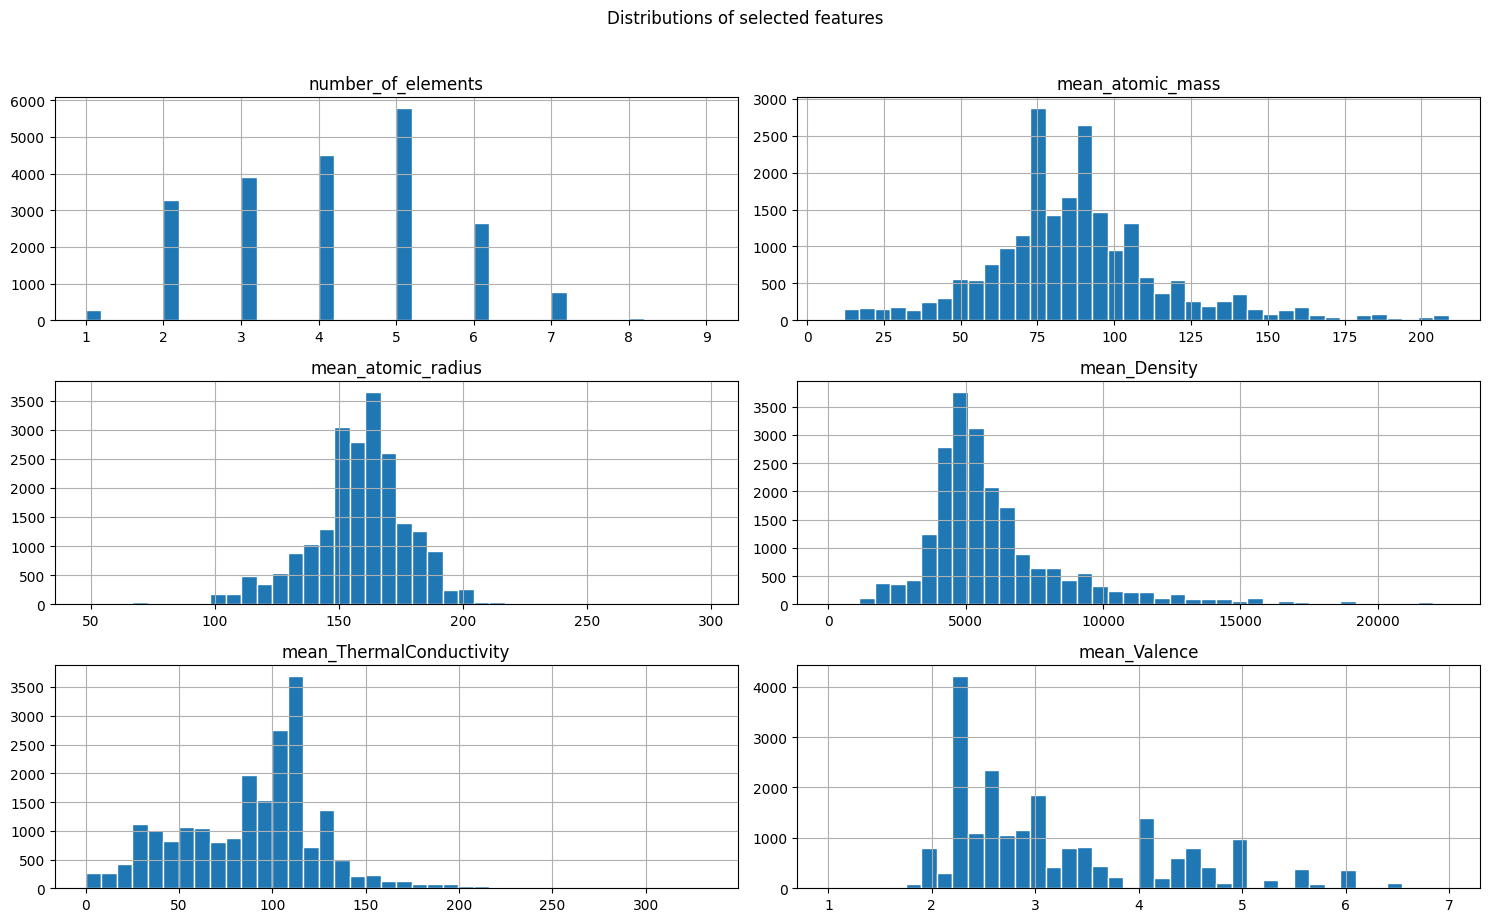

In [26]:
selected_features = [
    "number_of_elements",
    "mean_atomic_mass",
    "mean_atomic_radius",
    "mean_Density",
    "mean_ThermalConductivity",
    "mean_Valence"
]

train[selected_features].hist(
    bins=40,
    figsize=(15, 9),
    edgecolor="white"
)

plt.suptitle("Distributions of selected features", y=1.02)
plt.tight_layout()
plt.show()

,count,mean,median,std,min,max
number_of_elements,,,,,,
1,285,5.19,4.00,6.30,0.00,52.0
2,3280,5.76,3.90,7.37,0.00,185.0
3,3895,9.36,5.80,10.67,0.01,132.0
4,4496,36.55,24.30,32.91,0.00,130.0
5,5792,50.71,47.90,32.89,0.00,135.8
6,2666,59.63,62.40,32.01,0.10,143.0
7,774,66.83,68.00,31.53,2.70,136.0
8,61,86.52,96.80,27.61,20.00,123.5
9,14,73.23,74.82,14.38,45.30,92.9


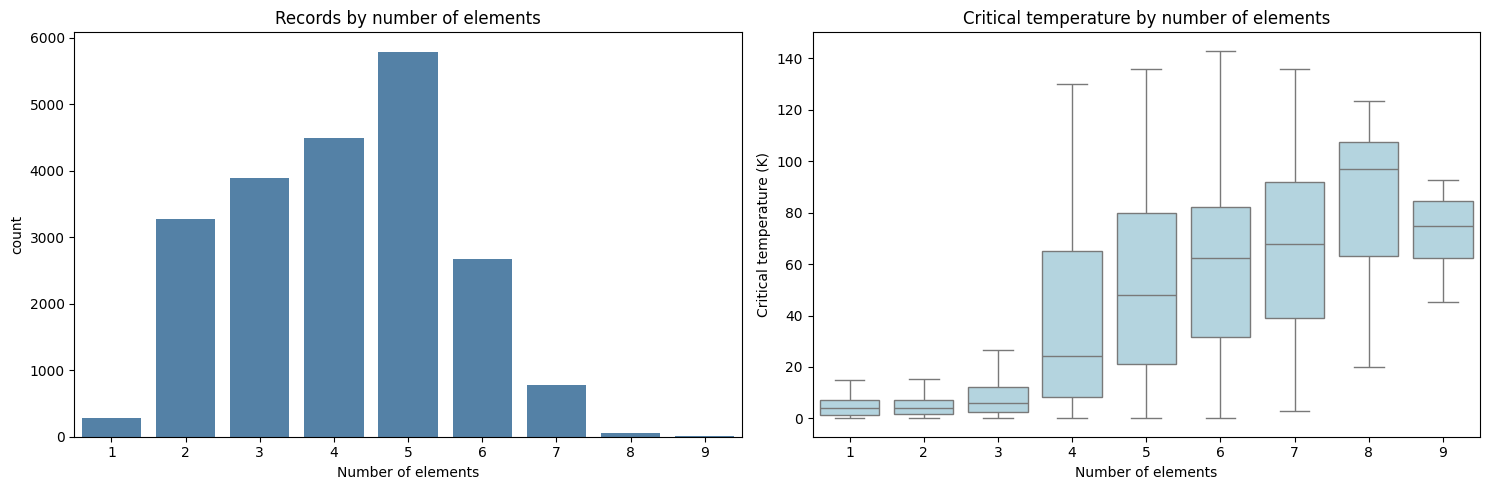

In [27]:
element_summary = (
    train.groupby("number_of_elements")["critical_temp"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(element_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(
    data=train,
    x="number_of_elements",
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Records by number of elements")
axes[0].set_xlabel("Number of elements")

sns.boxplot(
    data=train,
    x="number_of_elements",
    y="critical_temp",
    showfliers=False,
    color="lightblue",
    ax=axes[1]
)
axes[1].set_title("Critical temperature by number of elements")
axes[1].set_xlabel("Number of elements")
axes[1].set_ylabel("Critical temperature (K)")

plt.tight_layout()
plt.show()

,Pearson,Spearman,Absolute Pearson
wtd_std_ThermalConductivity,0.721,0.712,0.721
range_ThermalConductivity,0.688,0.719,0.688
range_atomic_radius,0.654,0.755,0.654
std_ThermalConductivity,0.654,0.623,0.654
wtd_mean_Valence,-0.632,-0.736,0.632
wtd_entropy_atomic_mass,0.627,0.707,0.627
wtd_gmean_Valence,-0.616,-0.736,0.616
wtd_entropy_atomic_radius,0.603,0.688,0.603
number_of_elements,0.601,0.669,0.601
range_fie,0.601,0.665,0.601


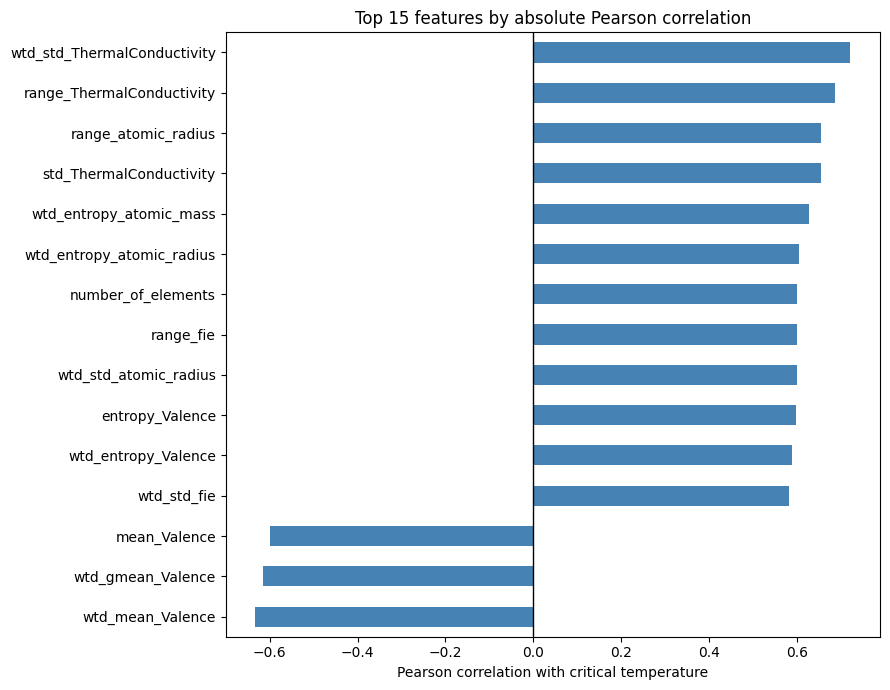

In [28]:
# Correlation describes association, not causation or model importance.
correlation_table = pd.DataFrame({
    "Pearson": train.corr(method="pearson")["critical_temp"],
    "Spearman": train.corr(method="spearman")["critical_temp"]
}).drop(index="critical_temp")

correlation_table["Absolute Pearson"] = (
    correlation_table["Pearson"].abs()
)

correlation_table = correlation_table.sort_values(
    "Absolute Pearson",
    ascending=False
)

display(correlation_table.head(15).round(3))

top_features = correlation_table.head(15).index

plt.figure(figsize=(9, 7))

correlation_table.loc[top_features, "Pearson"].sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Top 15 features by absolute Pearson correlation")
plt.xlabel("Pearson correlation with critical temperature")
plt.tight_layout()
plt.show()

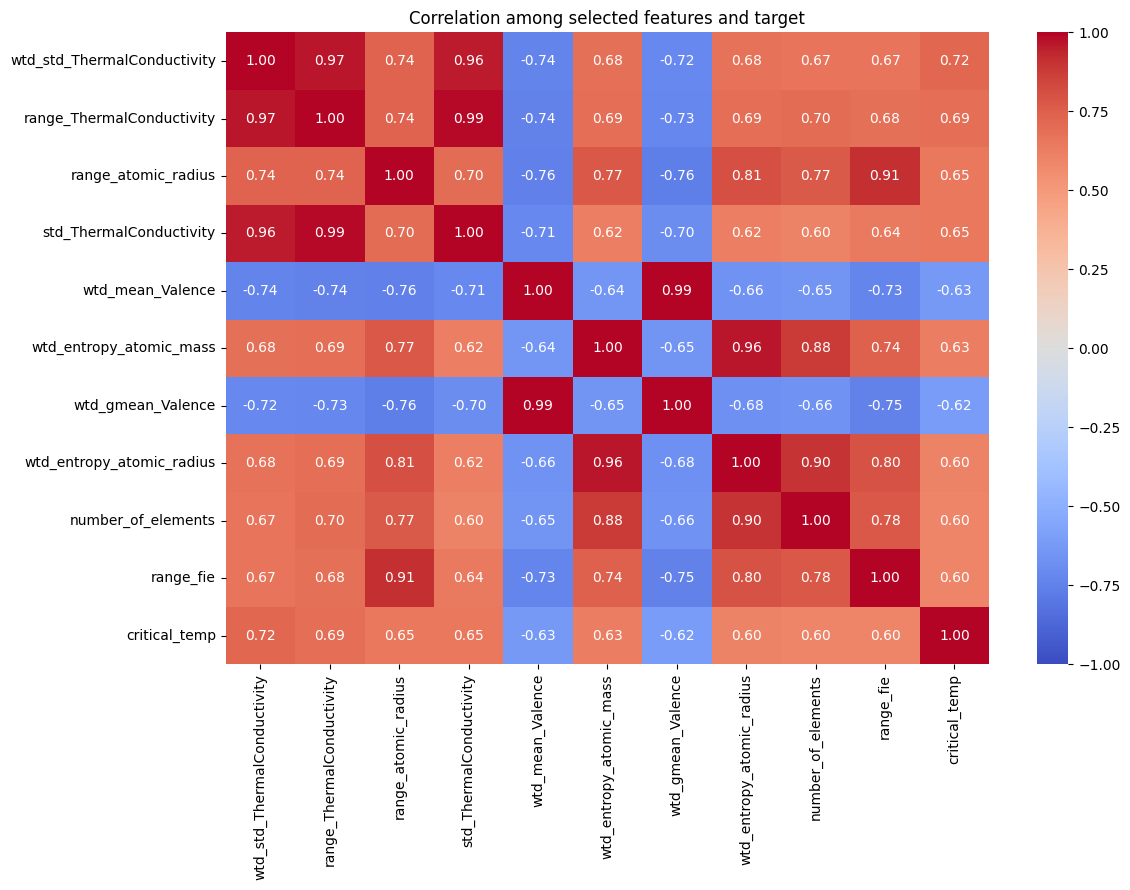

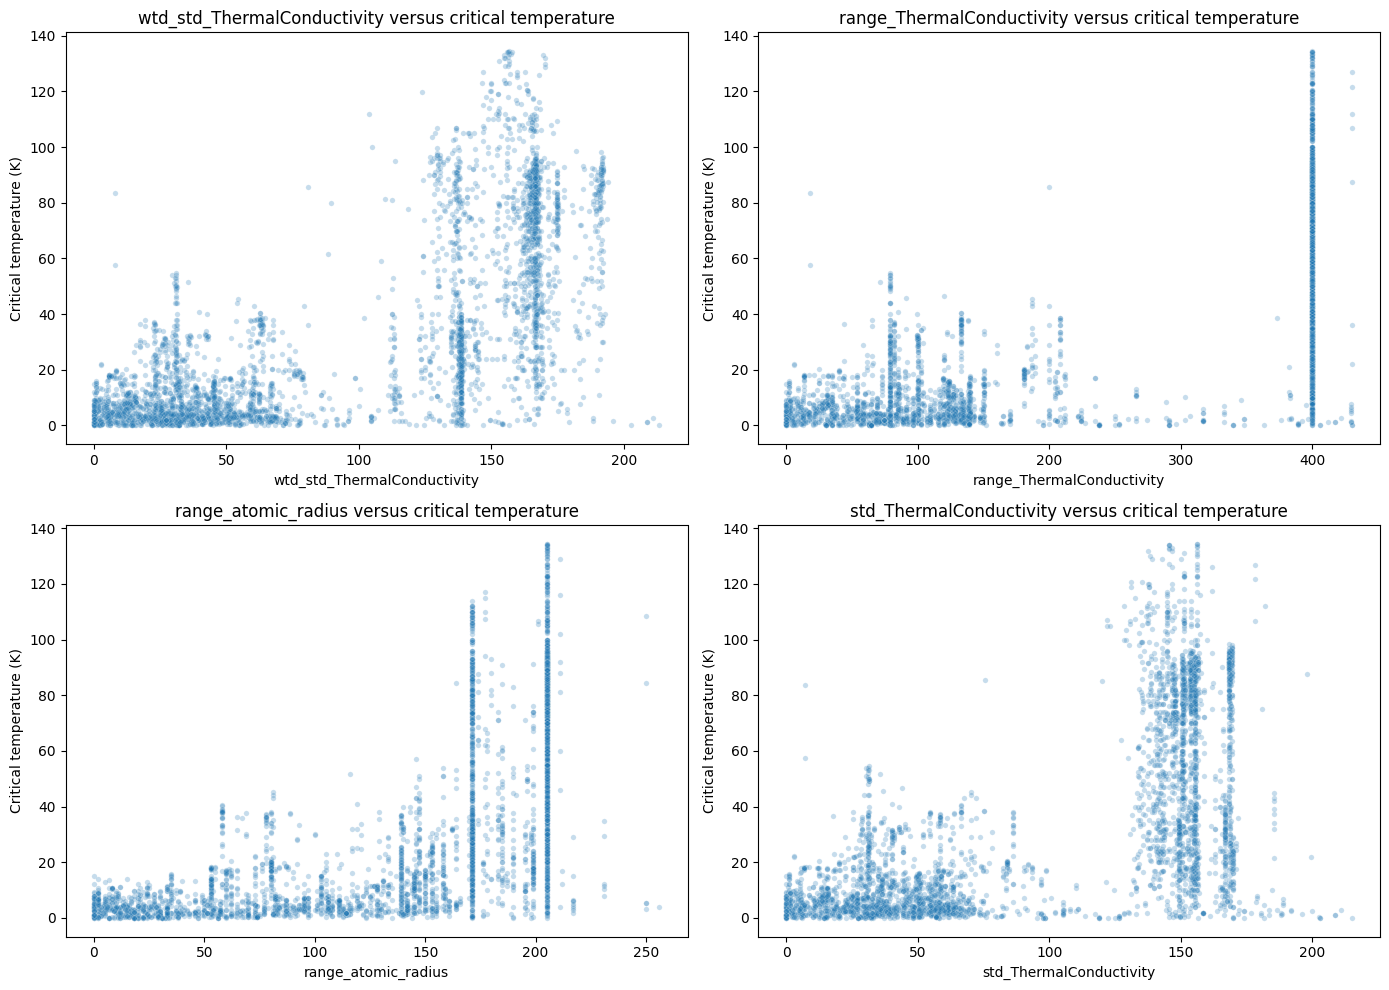

In [29]:
# A smaller heatmap is easier to read than all 81 features.
heatmap_features = correlation_table.head(10).index.tolist()
heatmap_columns = heatmap_features + ["critical_temp"]

plt.figure(figsize=(12, 9))

sns.heatmap(
    train[heatmap_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation among selected features and target")
plt.tight_layout()
plt.show()

# Sample only for clearer scatter plots; summaries use all records.
plot_sample = train.sample(n=min(4000, len(train)), random_state=42)
scatter_features = correlation_table.head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flat, scatter_features):
    sns.scatterplot(
        data=plot_sample,
        x=feature,
        y="critical_temp",
        alpha=0.25,
        s=15,
        ax=ax
    )
    ax.set_title(f"{feature} versus critical temperature")
    ax.set_ylabel("Critical temperature (K)")

plt.tight_layout()
plt.show()

,Records containing element,Percentage of records
O,11964,56.27
Cu,10838,50.97
Ba,6751,31.75
Sr,4852,22.82
Ca,4112,19.34
Y,4075,19.16
La,3463,16.29
Bi,2389,11.24
Fe,2339,11.00
As,1502,7.06


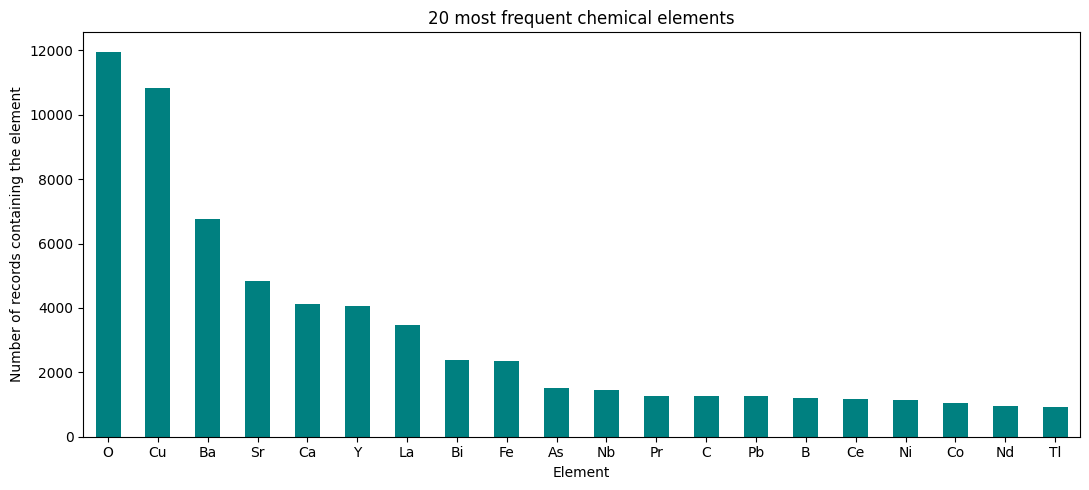

Rows with inconsistent element counts: 0


In [30]:
# Exclude the target and material identifier.
element_columns = composition.columns.drop(
    ["critical_temp", "material"]
)

# True means the element is present in that record.
presence = composition[element_columns].gt(0)

element_frequency = pd.DataFrame({
    "Records containing element": presence.sum(),
    "Percentage of records": presence.mean() * 100
}).sort_values(
    "Records containing element",
    ascending=False
)

display(element_frequency.head(20).round(2))

plt.figure(figsize=(11, 5))

element_frequency.head(20)["Records containing element"].plot(
    kind="bar",
    color="teal"
)

plt.title("20 most frequent chemical elements")
plt.xlabel("Element")
plt.ylabel("Number of records containing the element")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Cross-check calculated element counts against the composition file.
calculated_counts = presence.sum(axis=1)

print(
    "Rows with inconsistent element counts:",
    (calculated_counts != train["number_of_elements"]).sum()
)

## Classification: Random Forest, Logistic Regression, and Decision Tree

We classify whether a material has a **critical temperature of at least 77 K**. The threshold is an educational choice and can be changed below. Only features from `train.csv` are used; `critical_temp` and the material name are excluded from the inputs. Split before preprocessing; fit the imputer/scaler only on training data to avoid leakage.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

TEMPERATURE_THRESHOLD_K = 77.0  # Adjust if required
RANDOM_STATE = 42

X = train.drop(columns=["critical_temp"]).copy()
X = X.select_dtypes(include=np.number).replace([np.inf, -np.inf], np.nan)
y = (train["critical_temp"] >= TEMPERATURE_THRESHOLD_K).astype(int)

print("Target: 1 if critical_temp >=", TEMPERATURE_THRESHOLD_K, "K; otherwise 0")
print("Class counts:\n", y.value_counts().sort_index())
print("Class proportions:\n", y.value_counts(normalize=True).sort_index().round(3))
if y.nunique() != 2 or y.value_counts().min() < 2:
    raise ValueError("Both classes need at least two examples. Change the threshold.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", len(X_train), "Test size:", len(X_test))

Target: 1 if critical_temp >= 77.0 K; otherwise 0
Class counts:
 critical_temp
0    17311
1     3952
Name: count, dtype: int64
Class proportions:
 critical_temp
0    0.814
1    0.186
Name: proportion, dtype: float64
Train size: 17010 Test size: 4253


In [32]:
# Three models; preprocessing is learned on training data only.
models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1,
            class_weight="balanced"))
    ]),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(
            max_depth=10, min_samples_leaf=5, class_weight="balanced",
            random_state=RANDOM_STATE))
    ])
}

results = []
predictions = {}
probabilities = {}
for name, model in models.items():
    print("\nTraining:", name)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    predictions[name] = pred
    probabilities[name] = prob
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })
    print(classification_report(y_test, pred, target_names=[f"Below {TEMPERATURE_THRESHOLD_K:g}K", f"At least {TEMPERATURE_THRESHOLD_K:g}K"], zero_division=0))

results_df = pd.DataFrame(results).set_index("Model")
print("MODEL COMPARISON (positive class = at least threshold):")
display(results_df.round(4))


Training: Random Forest
              precision    recall  f1-score   support

   Below 77K       0.97      0.96      0.97      3463
At least 77K       0.84      0.86      0.85       790

    accuracy                           0.94      4253
   macro avg       0.90      0.91      0.91      4253
weighted avg       0.94      0.94      0.94      4253


Training: Logistic Regression
              precision    recall  f1-score   support

   Below 77K       0.99      0.82      0.90      3463
At least 77K       0.55      0.97      0.70       790

    accuracy                           0.85      4253
   macro avg       0.77      0.90      0.80      4253
weighted avg       0.91      0.85      0.86      4253


Training: Decision Tree
              precision    recall  f1-score   support

   Below 77K       0.99      0.87      0.93      3463
At least 77K       0.63      0.94      0.76       790

    accuracy                           0.89      4253
   macro avg       0.81      0.91      0.84    

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Random Forest,0.9436,0.8395,0.8608,0.8500,0.9797
Logistic Regression,0.8469,0.5497,0.9722,0.7023,0.9522
Decision Tree,0.8874,0.6319,0.9430,0.7567,0.9491


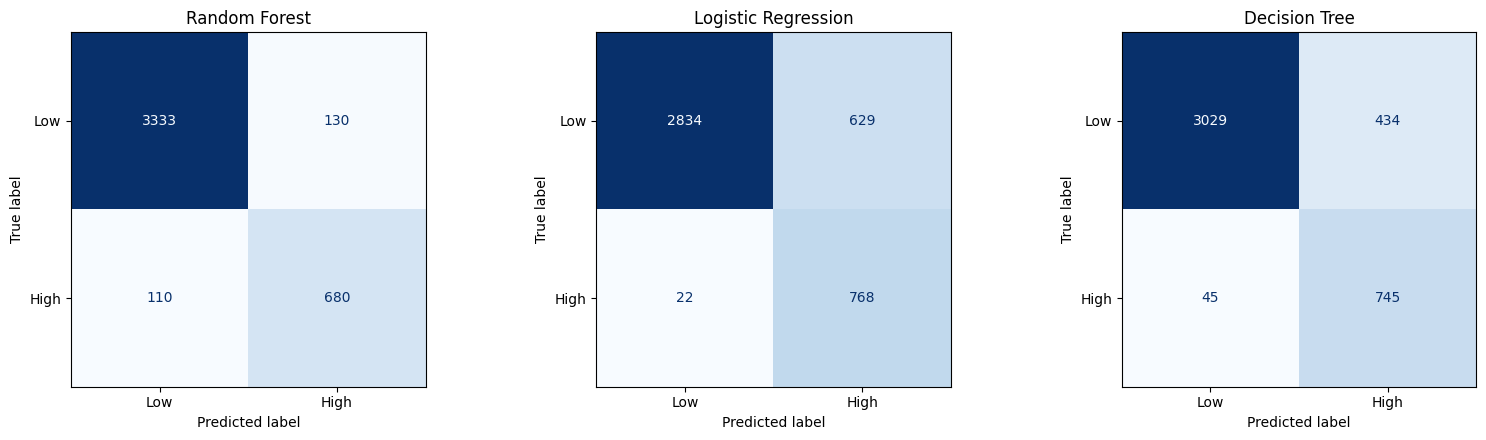

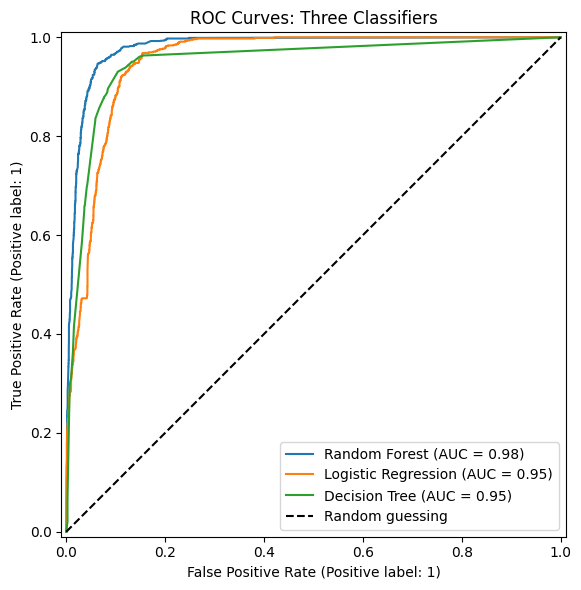

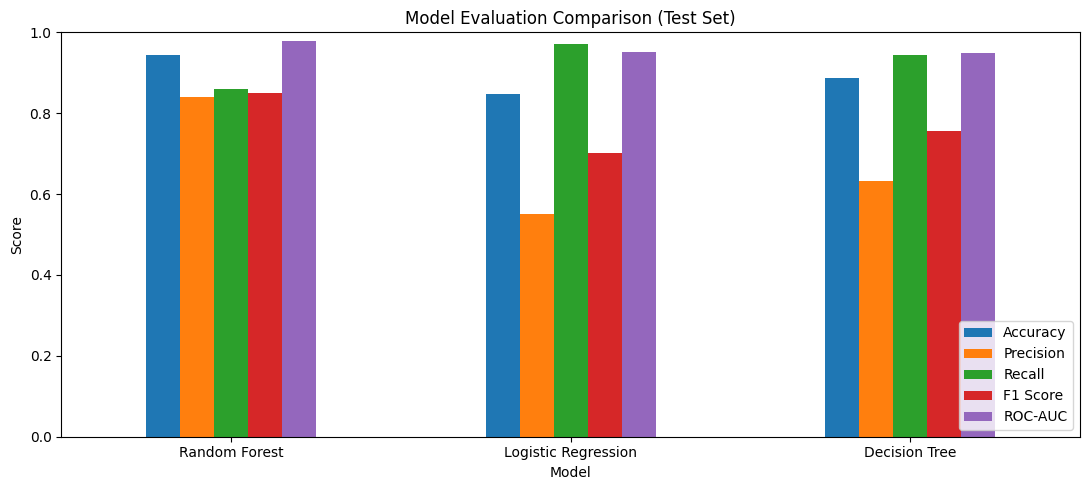

In [33]:
# Confusion matrices: rows = actual, columns = predicted.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["Low", "High"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ROC curves use probabilities, NOT hard class predictions.
fig, ax = plt.subplots(figsize=(8, 6))
for name, prob in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guessing")
ax.set_title("ROC Curves: Three Classifiers")
ax.legend()
plt.tight_layout()
plt.show()

# Easy-to-read comparison plot.
results_df.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0)
plt.title("Model Evaluation Comparison (Test Set)")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()